# Notebook zu: Kryptographie Entschlüsselt: Grundbegriffe und Klassische Verschlüsselungsverfahren

© 2001–2026 Gerald Teschl (http://www.mat.univie.ac.at/~gerald/) und Susanne Teschl (http://staff.technikum-wien.at/~teschl/)

Dieses [Python](https://python.org)-Notebook ist als Ergänzung zu unserem [Springer](https://www.springer.de/)-Lehrbuch "[Kryptographie Entschlüsselt](https://www.mat.univie.ac.at/~gerald/ftp/book-kry/)" gedacht. Dort finden Sie auch weitere Erklärungen.

Der Code kann bequem von [PyPI](https://pypi.org/project/kryptools/) installiert werden.

## Klassische Verschlüsselungsverfahren

### Caesar-Verschlüsselung

Verschlüsselung:

In [1]:
def caesar(x: str, e: int) -> str:
    "Rotate all letters in `x` by `e` places."
    e = e % 26
    y = ""
    for c in x:
        if c.isupper():
            y += chr((ord(c) + e - 65) % 26 + 65)
        elif c.islower():
            y += chr((ord(c) + e - 97) % 26 + 97)
        else:
            y += c
    return y


caesar("DIESPINNENDIEGALLIER", 3)

'GLHVSLQQHQGLHJDOOLHU'

Entschlüsselung:

In [2]:
caesar(_, -3)

'DIESPINNENDIEGALLIER'

Auszählen der Buchstabenhäufigkeiten:

In [3]:
def letter_freq(x: str) -> list[float]:
    "Determine the letter frequencies for the characters of a string `x`."
    lf = [0] * 26
    x = x.upper()
    for c in x:
        o = ord(c) - 65
        if 0 <= o <= 25:
            lf[o] += 1
    for i in range(26):
        lf[i] /= len(x)
    return lf

Bestimmen der vermutlichen Verschiebung über den häufigsten Buchstaben:

In [4]:
ciphertext = "INJXJWYJCYNXYSNHMYRJMWLJMJNR"

lf = letter_freq(ciphertext)
mfl = lf.index(max(lf))
e = (mfl - 4) % 26
print(chr(65 + mfl), e)
caesar(ciphertext, -e)

J 5


'DIESERTEXTISTNICHTMEHRGEHEIM'

Alternativ hier die Verschlüsselung mit XOR:

In [5]:
def xor1(m: bytes, key: int) -> bytes:
    """En-/decrypt a message by xoring with a key byte."""
    c = bytearray(b"")
    for x in m:
        c.append(x ^ key)
    return bytes(c)

plaintext = b"Streng Geheim!"
print([c for c in plaintext])
[ c for c in xor1(plaintext, 127) ]

[83, 116, 114, 101, 110, 103, 32, 71, 101, 104, 101, 105, 109, 33]


[44, 11, 13, 26, 17, 24, 95, 56, 26, 23, 26, 22, 18, 94]

### Buchstabenhäufigkeitsindex

Buchstabenhäufigkeiten für Englisch und Deutsch:

In [6]:
lf_en = [ 0.0804, 0.0148, 0.0334, 0.0382, 0.1249, 0.0240, 0.0187, 0.0505, 0.0757, 0.0016, 0.0054, 0.0407, 0.0251,
    0.0723, 0.0764, 0.0214, 0.0012, 0.0628, 0.0651, 0.0928, 0.0273, 0.0105, 0.0168, 0.0023, 0.0166, 0.0009 ]

lf_de = [ 0.0651, 0.0189, 0.0306, 0.0508, 0.174, 0.0166, 0.0301, 0.0476, 0.0755, 0.0027, 0.0121, 0.0344, 0.0253,
    0.0978, 0.0251, 0.0079, 0.0002, 0.07, 0.0727, 0.0615, 0.0435, 0.0067, 0.0189, 0.0003, 0.0004, 0.0113 ]

Berechnung des Buchstabenhäufigkeitsindexes eines Texts:

In [7]:
def lf_index(x: str | list[int]) -> int:
    "Compute the letter frequency index of a given string or list of letter frequencies `x`."
    if type(x) is str:
        x = letter_freq(x)
    K = 0.0
    n = len(x)
    for i in x:
        K += i**2
    K = (n / (n - 1)) * (K - 1 / n)
    return K


lf_index(ciphertext)

0.08469387755102041

Buchstabenhäufigkeitsindex eines deutschen

In [30]:
round(lf_index(lf_de), 3)

0.039

bzw. eines englischen

In [31]:
round(lf_index(lf_en), 3)

0.029

bzw. eines zufälligen Texts

In [32]:
round(lf_index([1 / 26] * 26), 3)

0.0

Erkennen, ob ein Text monoalphabetisch oder polyalphabetisch verschlüsselt wurde:

In [11]:
ciphertextm = 'UZQUZQYXQQDQZTMEQXEFDMGOTPMEUFLQZPDQUEBMFLQZNMGOTMZNMGOTPQDQDUOTDQOTFEGZPXUZWEPQDRDMZLGZPYUFFQZPDUZPQDRDQOTQTMZEEUQTMNQZPUQMGSQZLGSMZLLGGZPANQZPDNQDPMEOTZQUFQETGEUQDOWQZLGEMYYQZPUOTFMZPUOTFEAIMDYIUQTMZETMFEZUQYMZPZUOTFEUQTDZMXXQPDQUUTDQDTQDLXQUZSQBAOTGZPIQZZEUQZUOTFIQSEUZPEAEUFLQZEUQZAOT'
ciphertextp = 'UBVORREEIVEQBYGWRDLXINGQYJEFAMDVAPFVOWCSMDVANOLILNFUELPTRVXIEAVLIROVKYYAVEMEXERVXJESGDLAPAZZXRFWVZAPSILVRUAIYNZGJOIUSUIEQUSRAKRFSYXNZNQAYAVHFVAPFSKVQSLGYAQWKKWUMLMVEOYVTDHKTQDRZRZILGSGHZPTHJUANJFAZRTOEYLNLLRZRYOEJRVUAXJVQVITEYDXHIRUWYXIEZXVQYQWEMICGVLLAPKVTRFAXRZPTHNKKFAGHJBEWKFIAKBIEBOV'

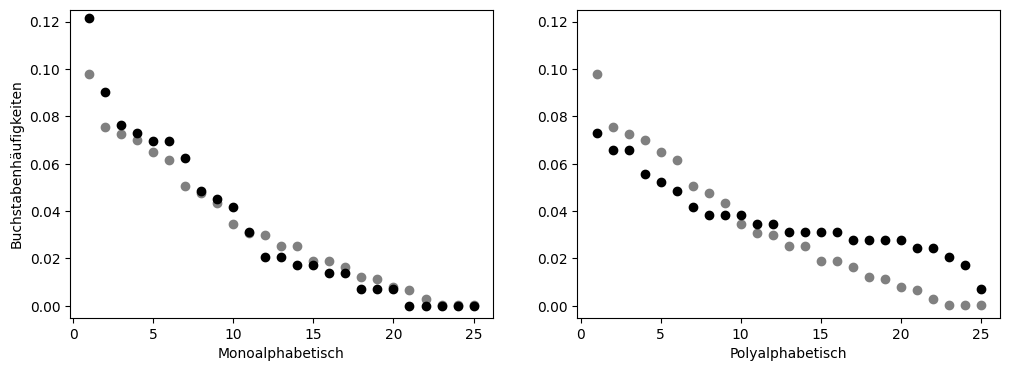

In [12]:
# requires "pip install matplotlib"
from matplotlib import pyplot as plt

slf_de = [ f for f in lf_de ]
slf_de.sort(reverse=True)
slf_ctp = letter_freq(ciphertextp)
slf_ctp.sort(reverse=True)
slf_ctm = letter_freq(ciphertextm)
slf_ctm.sort(reverse=True)

plt.figure(figsize=(12,4))
plt.subplot(1, 2, 1)
plt.ylim(-0.005, 0.125)
plt.scatter(range(1, 26), [slf_de[i] for i in range(1, 26)], color="grey")
plt.scatter(range(1, 26), [slf_ctm[i] for i in range(1, 26)], color="black")
plt.xlabel("Monoalphabetisch")
plt.ylabel("Buchstabenhäufigkeiten")
plt.subplot(1, 2, 2)
plt.ylim(-0.005, 0.125)
plt.scatter(range(1, 26), [slf_de[i] for i in range(1, 26)], color="grey")
plt.scatter(range(1, 26), [slf_ctp[i] for i in range(1, 26)], color="black")
plt.xlabel("Polyalphabetisch")
#plt.ylabel("Buchstabenhäufigkeiten")

#plt.savefig("letterfreq.pdf", format="pdf", bbox_inches='tight')
plt.show()

In [33]:
round(lf_index(ciphertextm), 3), round(lf_index(ciphertextp), 3)

(0.041, 0.008)

### Automatisierte Strategien

Ermittlung der Verschiebung durch Aufsuchen der minimalen quadratischen Abweichungen der [Buchstabenhäufigkeiten](https://de.wikipedia.org/wiki/Buchstabenhäufigkeit) zur vermuteten Sprache (Kosinus-Ähnlichkeit):

In [35]:
def caesar_crack(y: str, lfx: list) -> int:
    "Find the most likely key of a Caesar ecrypted string `y` given the expected letter frequencies `lfx`."
    lf = letter_freq(y)
    dmin = 26
    emin = -1
    for e in range(26):
        d = 0
        for i in range(26):
            d += (lf[(i + e) % 26] - lfx[i]) ** 2
        if d < dmin:
            dmin = d
            emin = e
    return emin


ciphertext = "PUQMZFIADFMGRPUQRDMSQZMOTPQYXQNQZPQYGZUHQDEGYGZPPQYSMZLQZDQEFUEFLIQUGZPHUQDLUS"
e = caesar_crack(ciphertext, lf_de)
print(f"e = {e}")
caesar(ciphertext, -e)

e = 12


'DIEANTWORTAUFDIEFRAGENACHDEMLEBENDEMUNIVERSUMUNDDEMGANZENRESTISTZWEIUNDVIERZIG'

### Vigenère-Verschlüsselung

Verschlüsseln

In [15]:
def vigenere(x: str, p: str, invert: bool = False) -> str:
    "Vigenere encrypt or decrypt a string `x` using the password `p`."
    key = []
    for c in p.upper():
        o = (ord(c) - 65) % 26
        if invert:
            key.append(-o)
        else:
            key.append(o)
    lk = len(key)
    y = ""
    for i, c in enumerate(x):
        if c.isupper():
            y += chr((ord(c) + key[i % lk] - 65) % 26 + 65)
        elif c.islower():
            y += chr((ord(c) + key[i % lk] - 97) % 26 + 97)
        else:
            y += c
    return y


vigenere("DIESERTEXTISTGEHEIM", "VIGENERE")

'YQKWRVKISBOWGKVLZQS'

Entschlüsseln

In [16]:
vigenere(_, "VIGENERE", invert=True)

'DIESERTEXTISTGEHEIM'

Zerlegen eines Texts

In [17]:
def split_string(x: str, n: int) -> list[str]:
    "Split a string `x` into letters of distance `n`."
    return [x[i::n] for i in range(n)]


split_string("aAbBcCd", 2)

['abcd', 'ABC']

Durchschnittlicher Buchstabenhäufigkeitsindex der Zerlegung

In [18]:
def lf_index2(x, n):
    xx = split_string(x, n)
    lfi = 0
    for i in range(n):
        lfi += lf_index(xx[i])
    lfi = lfi / n
    return lfi


lf_index2("aabbcc", 2)

0.30666666666666664

Hier ist der Geheimtext, den wir entschlüsseln wollen:

In [19]:
# German example
ciphertext = "UBVORREEIVEQBYGWRDLXINGQYJEFAMDVAPFVOWCSMDVANOLILNFUELPTRVXIEAVLIROVKYYAVEMEXERVXJESGDLAPAZZXRFWVZAPSILVRUAIYNZGJOIUSUIEQUSRAKRFSYXNZNQAYAVHFVAPFSKVQSLGYAQWKKWUMLMVEOYVTDHKTQDRZRZILGSGHZPTHJUANJFAZRTOEYLNLLRZRYOEJRVUAXJVQVITEYDXHIRUWYXIEZXVQYQWEMICGVLLAPKVTRFAXRZPTHNKKFAGHJBEWKFIAKBIEBOV"

Visualisierung:

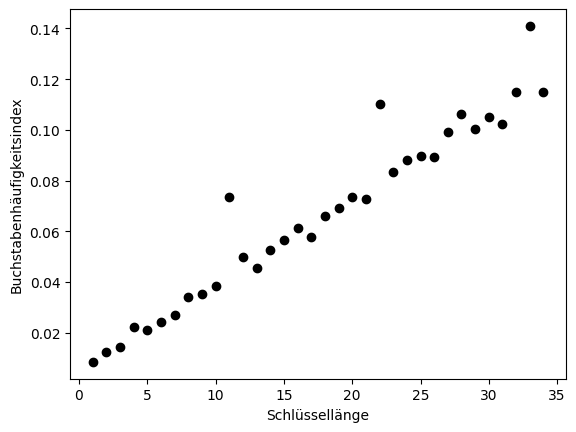

In [20]:
# requires "pip install matplotlib"
from matplotlib import pyplot as plt

n = 35
plt.scatter(range(1, n), [lf_index2(ciphertext, i) for i in range(1, n)], color="black")
plt.xlabel("Schlüssellänge")
plt.ylabel("Buchstabenhäufigkeitsindex")
#plt.savefig("morgenstern.pdf", format="pdf", bbox_inches='tight')
plt.show()

Da die Maxima bei 11, 22, 33 liegen, ist die Schlüssellänge vermutlich gleich 11.

In [21]:
n = 11
c = split_string(ciphertext, n)
p = ""
for i in range(n):
    p += chr(caesar_crack(c[i], lf_de) + 65)
pi = ""
for l in [chr((26 - ord(l)+65)+65) for l in p]:
    pi += l
print(p, pi)

MORGENSTERN OMJUWNIHWJN


Der entschlüsselte Text

In [22]:
vigenere(ciphertext, p, invert=True)

'INEINEMLEERENHASELSTRAUCHDASITZENDREISPATZENBAUCHANBAUCHDERERICHRECHTSUNDLINKSDERFRANZUNDMITTENDRINDERFRECHEHANSSIEHABENDIEAUGENZUGANZZUUNDOBENDRBERDASCHNEITESHUSIERCKENZUSAMMENDICHTANDICHTSOWARMWIEHANSHATSNIEMANDNICHTSIEHRNALLEDREIIHRERHERZLEINGEPOCHUNDWENNSIENICHTWEGSINDSOSITZENSIENOCH'

### RC4

Die Stromchiffre RC4

In [26]:
class RC4:
    def __init__(self, key):
        self.S = [i for i in range(256)]

        if isinstance(key, str):
            key = key.encode() #  we need a bytestring
        keylen = len(key)
        j = 0
        for i in range(256):
            j = (j + self.S[i] + key[i % keylen]) % 256
            self.S[i], self.S[j] = self.S[j], self.S[i]
        self.j = 0
        self.i = 0

    def next(self):
        i = (self.i + 1) % 256
        j = (self.j + self.S[i]) % 256
        self.S[i], self.S[j] = self.S[j], self.S[i]
        self.i = i
        self.j = j
        return self.S[(self.S[i] + self.S[j]) % 256]

Erzeugung des Schlüsselstroms:

In [27]:
rc4 = RC4('Key')
out= bytearray(b'')
for i in range(10):
    out.append(rc4.next())
out.hex()

'eb9f7781b734ca72a719'

Verschlüsselung einer Nachricht

In [28]:
rc4 = RC4('Key')
text='Plaintext'
out=bytearray(b'')

text=text.encode() #  we need a bytestring
for i in range(len(text)):
    out.append(text[i] ^ rc4.next())

out.hex()

'bbf316e8d940af0ad3'

Entschlüsselung

In [29]:
rc4 = RC4('Key')
text=bytearray(b'')

for i in range(len(out)):
    text.append(out[i] ^ rc4.next())

text.decode()

'Plaintext'